In [5]:
import argparse
import csv
import hashlib
import json
import math
import shutil
import time
from datetime import datetime
from collections import Counter, defaultdict
from pathlib import Path, PureWindowsPath

import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.layers import Bidirectional, Dense, Dropout, Input, LSTM, Masking
from tensorflow.keras.models import Sequential

In [6]:
INPUT = Path(r"D:\Sistem Skripsi\Google Colab\features_motion")
feature_manifest_generator = (
    path for path in INPUT.rglob("feature_manifest.csv")
    if "features_motion" in str(path)
)
FEATURE_MANIFEST = next(feature_manifest_generator, None)

if FEATURE_MANIFEST is None:
    raise FileNotFoundError(
        f"Could not find 'feature_manifest.csv' under '{INPUT}' "
        "that contains 'features_motion' in its path. "
        "Please ensure the file exists and the path is correct."
    )

FEATURE_ROOT = FEATURE_MANIFEST.parent
CACHE_ROOT = Path(r"D:\Sistem Skripsi\Google Colab\training_cache")
ARTIFACT_ROOT = Path(r"D:\Sistem Skripsi\Google Colab\model_artifacts")

print("GPU:", tf.config.list_physical_devices("GPU"))
print("Feature manifest:", FEATURE_MANIFEST)

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Feature manifest: /content/drive/MyDrive/KDRT/features_motion/feature_manifest.csv


In [7]:
def find_project_root():
    current_dir = Path.cwd().resolve()
    for candidate in [current_dir, *current_dir.parents]:
        if (candidate / "Laporan Final").is_dir() and (candidate / "Website").is_dir():
            return candidate
    return current_dir


ROOT_DIR = find_project_root()
EXPERIMENT_ROOT = ROOT_DIR / "Laporan Final" / "Dataset" / "Legacy_v2"
DEFAULT_FEATURE_MANIFEST = EXPERIMENT_ROOT / "features" / "feature_manifest.csv"
DEFAULT_ARTIFACTS = EXPERIMENT_ROOT / "model_artifacts"
DEFAULT_CACHE = EXPERIMENT_ROOT / "training_cache"

SEQUENCE_LENGTH = 20
FEATURE_SIZE = 1280
RANDOM_SEED = 42
THRESHOLDS = np.arange(0.10, 0.901, 0.01)
AGGREGATORS = ["mean", "median", "max", "top2_mean", "top3_mean"]

CONFIGURATIONS = [
    {
        "architecture": "baseline",
        "dropout": dropout,
        "loss": loss,
        "batch_size": batch_size,
        "learning_rate": learning_rate,
    }
    for dropout in [0.4, 0.5, 0.6]
    for batch_size in [16, 32]
    for learning_rate in [1e-4, 3e-4]
    for loss in ["weighted_bce", "focal"]
]


def write_csv(path, data, fields):
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=fields, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(data)


def human_duration(seconds):
    seconds = max(float(seconds), 0.0)
    hours, remainder = divmod(int(seconds), 3600)
    minutes, secs = divmod(remainder, 60)
    return f"{hours:02d}:{minutes:02d}:{secs:02d}"


def gpu_memory_mb():
    try:
        info = tf.config.experimental.get_memory_info("GPU:0")
        return (
            round(info["current"] / 1024**2, 1),
            round(info["peak"] / 1024**2, 1),
        )
    except Exception:
        return (None, None)


def append_monitor_row(path, row):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    write_header = not path.exists()
    with path.open("a", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(row.keys()))
        if write_header:
            writer.writeheader()
        writer.writerow(row)


class KaggleTrainingMonitor(tf.keras.callbacks.Callback):
    """Monitor per epoch: loss, metrics, learning rate, ETA, and GPU memory."""
    def __init__(self, experiment_id, total_epochs, monitor_path):
        super().__init__()
        self.experiment_id = experiment_id
        self.total_epochs = total_epochs
        self.monitor_path = Path(monitor_path)
        self.started = None

    def on_train_begin(self, logs=None):
        self.started = time.perf_counter()
        print(f"[MODEL START] {self.experiment_id} | epoch={self.total_epochs}", flush=True)

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        done = epoch + 1
        elapsed = time.perf_counter() - self.started
        eta = (elapsed / done) * max(self.total_epochs - done, 0)
        lr = float(tf.keras.backend.get_value(self.model.optimizer.learning_rate))
        gpu_current, gpu_peak = gpu_memory_mb()
        row = {
            "timestamp": datetime.now().isoformat(timespec="seconds"),
            "experiment_id": self.experiment_id,
            "epoch": done,
            "epoch_total": self.total_epochs,
            "progress_percent": round(100 * done / max(self.total_epochs, 1), 2),
            "loss": logs.get("loss"),
            "val_loss": logs.get("val_loss"),
            "accuracy": logs.get("accuracy"),
            "val_accuracy": logs.get("val_accuracy"),
            "learning_rate": lr,
            "elapsed_seconds": round(elapsed, 1),
            "eta_seconds": round(eta, 1),
            "gpu_current_mb": gpu_current,
            "gpu_peak_mb": gpu_peak,
        }
        append_monitor_row(self.monitor_path, row)
        print(
            f"[TRAINING MONITOR] {self.experiment_id} | epoch {done}/{self.total_epochs} "
            f"({row['progress_percent']:.1f}%) | loss={logs.get('loss', float('nan')):.4f} | "
            f"val_loss={logs.get('val_loss', float('nan')):.4f} | "
            f"lr={lr:.2e} | elapsed={human_duration(elapsed)} | ETA={human_duration(eta)} | "
            f"GPU={gpu_current}/{gpu_peak} MB",
            flush=True,
        )


def read_feature_manifest(path, feature_root=None):
    with path.open(newline="", encoding="utf-8") as handle:
        rows = list(csv.DictReader(handle))
    usable = []
    for row in rows:
        if row["status"] not in {"processed", "skipped_existing"}:
            continue
        if row["split"] != "train" and row["variant"] != "original":
            continue
        raw_feature_path = row["feature_path"]
        feature_path = Path(raw_feature_path)
        if not feature_path.exists() and feature_root is not None:
            feature_name = (
                PureWindowsPath(raw_feature_path).name
                if "\\" in raw_feature_path
                else feature_path.name
            )
            feature_path = (
                feature_root / row["split"] / row["label"] / row["source"]
                / feature_name
            )
        row["feature_path"] = str(feature_path)
        row["target"] = 1 if row["label"] == "Fight" else 0
        usable.append(row)
    return usable


def manifest_hash(rows):
    digest = hashlib.sha256()
    for row in rows:
        digest.update(
            f"{row['feature_path']}|{row['split']}|{row['label']}|{row['video_id']}\n".encode("utf-8")
        )
    return digest.hexdigest()


def build_cache(rows, split, cache_dir):
    selected = [row for row in rows if row["split"] == split]
    if not selected:
        raise RuntimeError(f"Features for split {split} are not available.")
    cache_dir.mkdir(parents=True, exist_ok=True)
    x_path = cache_dir / f"x_{split}.npy"
    y_path = cache_dir / f"y_{split}.npy"
    metadata_path = cache_dir / f"metadata_{split}.csv"
    version_path = cache_dir / f"version_{split}.json"
    expected_hash = manifest_hash(selected)
    reusable = False
    if x_path.exists() and y_path.exists() and metadata_path.exists() and version_path.exists():
        try:
            version = json.loads(version_path.read_text(encoding="utf-8"))
            x_value = np.load(x_path, mmap_mode="r")
            y_value = np.load(y_path, mmap_mode="r")
            reusable = (
                version["manifest_hash"] == expected_hash
                and x_value.shape == (len(selected), SEQUENCE_LENGTH, FEATURE_SIZE)
                and y_value.shape == (len(selected),)
            )
        except Exception:
            reusable = False
    if not reusable:
        x_value = np.lib.format.open_memmap(
            x_path,
            mode="w+",
            dtype=np.float16,
            shape=(len(selected), SEQUENCE_LENGTH, FEATURE_SIZE),
        )
        y_value = np.lib.format.open_memmap(y_path, mode="w+", dtype=np.uint8, shape=(len(selected),))
        for index, row in enumerate(selected):
            value = np.load(row["feature_path"])
            if value.shape != (SEQUENCE_LENGTH, FEATURE_SIZE) or not np.isfinite(value).all():
                raise RuntimeError(f"Invalid feature: {row['feature_path']} {value.shape}")
            x_value[index] = value.astype(np.float16)
            y_value[index] = row["target"]
            if (index + 1) % 500 == 0:
                x_value.flush()
                y_value.flush()
        x_value.flush()
        y_value.flush()
        write_csv(metadata_path, selected, list(selected[0].keys()))
        version_path.write_text(
            json.dumps({"manifest_hash": expected_hash, "samples": len(selected), "dtype": "float16"}, indent=2),
            encoding="utf-8",
        )
    with metadata_path.open(newline="", encoding="utf-8") as handle:
        metadata = list(csv.DictReader(handle))
    return (
        np.load(x_path, mmap_mode="r"),
        np.load(y_path, mmap_mode="r"),
        metadata,
    )


class ArraySequence(tf.keras.utils.Sequence):
    def __init__(self, x, y, batch_size, indices=None, sample_probabilities=None,
                 sample_weights=None, seed=42):
        super().__init__()
        self.x = x
        self.y = y
        self.batch_size = batch_size
        self.base_indices = np.arange(len(y)) if indices is None else np.asarray(indices, dtype=np.int64)
        self.sample_probabilities = sample_probabilities
        self.sample_weights = sample_weights
        self.rng = np.random.default_rng(seed)
        self.epoch_indices = self.base_indices.copy()
        self.resample = sample_probabilities is not None
        self.on_epoch_end()

    def __len__(self):
        return math.ceil(len(self.base_indices) / self.batch_size)

    def __getitem__(self, batch_index):
        start = batch_index * self.batch_size
        selected = self.epoch_indices[start:start + self.batch_size]
        x_batch = np.asarray(self.x[selected], dtype=np.float32)
        y_batch = np.asarray(self.y[selected], dtype=np.float32)
        if self.sample_weights is None:
            return x_batch, y_batch
        return x_batch, y_batch, np.asarray(self.sample_weights[selected], dtype=np.float32)

    def on_epoch_end(self):
        if self.resample:
            self.epoch_indices = self.rng.choice(
                self.base_indices,
                size=len(self.base_indices),
                replace=True,
                p=self.sample_probabilities,
            )
        else:
            self.epoch_indices = self.base_indices.copy()


def balanced_probabilities(metadata):
    buckets = defaultdict(list)
    video_windows = Counter(row["video_id"] for row in metadata)
    bucket_videos = defaultdict(set)
    for index, row in enumerate(metadata):
        key = (row["source"], row["label"])
        buckets[key].append(index)
        bucket_videos[key].add(row["video_id"])
    raw = np.zeros(len(metadata), dtype=np.float64)
    for key, indices in buckets.items():
        bucket_weight = 1.0 / len(bucket_videos[key])
        for index in indices:
            raw[index] = bucket_weight / video_windows[metadata[index]["video_id"]]
    raw /= raw.sum()
    return raw, {f"{source}:{label}": len(videos) for (source, label), videos in bucket_videos.items()}


def build_model(architecture, dropout, loss_name, learning_rate):
    layers = [Input(shape=(SEQUENCE_LENGTH, FEATURE_SIZE)), Masking(mask_value=0.0)]
    if architecture == "bidirectional":
        layers.append(Bidirectional(LSTM(128, return_sequences=True)))
    else:
        layers.append(LSTM(128, return_sequences=True))
    layers.extend([Dropout(dropout), LSTM(64), Dropout(dropout), Dense(64, activation="relu"), Dense(1, activation="sigmoid")])
    model = Sequential(layers)
    loss = (
        tf.keras.losses.BinaryFocalCrossentropy(
            gamma=2.0, apply_class_balancing=True, alpha=0.40
        )
        if loss_name == "focal"
        else "binary_crossentropy"
    )
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=loss,
        metrics=["accuracy"],
    )
    return model


def aggregate(values, method):
    ordered = np.sort(np.asarray(values, dtype=np.float64))[::-1]
    if method == "mean":
        return float(np.mean(ordered))
    if method == "median":
        return float(np.median(ordered))
    if method == "max":
        return float(ordered[0])
    if method == "top2_mean":
        return float(np.mean(ordered[: min(2, len(ordered))]))
    if method == "top3_mean":
        return float(np.mean(ordered[: min(3, len(ordered))]))
    raise ValueError(method)


def aggregate_video_predictions(probabilities, metadata, method):
    grouped = defaultdict(list)
    details = {}
    for probability, row in zip(probabilities, metadata):
        grouped[row["video_id"]].append(float(probability))
        details[row["video_id"]] = row
    output = []
    for video_id, values in grouped.items():
        row = details[video_id]
        output.append({
            "video_id": video_id,
            "source": row["source"],
            "label": row["label"],
            "actual": 1 if row["label"] == "Fight" else 0,
            "windows": len(values),
            "probability": aggregate(values, method),
        })
    return output


def metrics(actual, predicted):
    tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if tn + fp else 0.0
    return {
        "accuracy": float(accuracy_score(actual, predicted)),
        "precision": float(precision_score(actual, predicted, zero_division=0)),
        "recall": float(recall_score(actual, predicted, zero_division=0)),
        "specificity": float(specificity),
        "f1_score": float(f1_score(actual, predicted, zero_division=0)),
        "true_positive": int(tp),
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
    }


def evaluate_video_rows(video_rows, threshold):
    actual = np.asarray([row["actual"] for row in video_rows], dtype=np.int32)
    predicted = np.asarray([row["probability"] >= threshold for row in video_rows], dtype=np.int32)
    overall = metrics(actual, predicted)
    source_f1 = []
    for source in ["RealLife", "RWF2000", "Surveillance"]:
        indices = [index for index, row in enumerate(video_rows) if row["source"] == source]
        if indices:
            source_metrics = metrics(actual[indices], predicted[indices])
            source_f1.append(source_metrics["f1_score"])
    overall["macro_source_f1"] = float(np.mean(source_f1)) if source_f1 else 0.0
    return overall, predicted


def optimize_validation(probabilities, metadata):
    results = []
    for aggregator in AGGREGATORS:
        video_rows = aggregate_video_predictions(probabilities, metadata, aggregator)
        for threshold in THRESHOLDS:
            score, _ = evaluate_video_rows(video_rows, float(threshold))
            results.append({
                "aggregator": aggregator,
                "threshold": round(float(threshold), 2),
                "videos": len(video_rows),
                **{key: round(value, 6) if isinstance(value, float) else value for key, value in score.items()},
            })
    feasible = [
        row for row in results
        if min(
            row["accuracy"], row["precision"], row["recall"],
            row["specificity"], row["f1_score"],
        ) > 0.90
    ]
    pool = feasible or results
    best = max(
        pool,
        key=lambda row: (
            min(row["accuracy"], row["precision"], row["recall"], row["specificity"], row["f1_score"]),
            row["macro_source_f1"], row["f1_score"], row["recall"], row["accuracy"],
        ),
    )
    best["all_metrics_above_90"] = bool(feasible)
    return best, results


def predict(model, x, y, batch_size):
    sequence = ArraySequence(x, y, batch_size=batch_size)
    return model.predict(sequence, verbose=0).reshape(-1)[: len(y)]


def train_configuration(config, datasets, artifact_dir, epochs, sampling_probabilities):
    batch_size = int(config["batch_size"])
    learning_rate = float(config["learning_rate"])
    experiment_id = (
        f"{config['architecture']}_d{config['dropout']:.1f}_{config['loss']}"
        f"_b{batch_size}_lr{learning_rate:g}"
    )
    history_path = artifact_dir / "history" / f"{experiment_id}.csv"
    checkpoint = artifact_dir / "checkpoints" / f"{experiment_id}.weights.h5"
    history_path.parent.mkdir(parents=True, exist_ok=True)
    checkpoint.parent.mkdir(parents=True, exist_ok=True)
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(RANDOM_SEED)
    model = build_model(config["architecture"], config["dropout"], config["loss"], learning_rate)
    x_train, y_train, _ = datasets["train"]
    x_validation, y_validation, validation_metadata = datasets["validation"]
    train_sequence = ArraySequence(
        x_train,
        y_train,
        batch_size=batch_size,
        sample_probabilities=sampling_probabilities,
        sample_weights=(
            np.where(np.asarray(y_train) == 0, 1.25, 1.0)
            if config["loss"] == "weighted_bce" else None
        ),
        seed=RANDOM_SEED,
    )
    validation_sequence = ArraySequence(x_validation, y_validation, batch_size=batch_size)
    started = time.perf_counter()
    history = model.fit(
        train_sequence,
        validation_data=validation_sequence,
        epochs=epochs,
        callbacks=[
            KaggleTrainingMonitor(
                experiment_id=experiment_id,
                total_epochs=epochs,
                monitor_path=artifact_dir / "training_epoch_monitor.csv",
            ),
            CSVLogger(str(history_path)),
            ModelCheckpoint(str(checkpoint), monitor="val_loss", mode="min", save_best_only=True, save_weights_only=True),
            EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
            ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
        ],
        verbose=2,
    )
    model.load_weights(checkpoint)
    probabilities = predict(model, x_validation, y_validation, batch_size)
    best_validation, threshold_rows = optimize_validation(probabilities, validation_metadata)
    write_csv(
        artifact_dir / "validation" / f"{experiment_id}.csv",
        threshold_rows,
        list(threshold_rows[0].keys()),
    )
    best_epoch = int(np.argmin(history.history["val_loss"])) + 1
    result = {
        "experiment_id": experiment_id,
        **config,
        "best_epoch": best_epoch,
        "best_val_loss": round(float(min(history.history["val_loss"])), 6),
        "duration_seconds": round(time.perf_counter() - started, 3),
        **{f"validation_{key}": value for key, value in best_validation.items()},
    }
    print(
        f"[MODEL RESULT] {experiment_id} | best_epoch={best_epoch} | "
        f"val_f1={result.get('validation_f1_score', 0):.4f} | "
        f"duration={human_duration(result['duration_seconds'])}",
        flush=True,
    )
    return result


def source_metrics(video_rows, predicted):
    output = []
    actual = np.asarray([row["actual"] for row in video_rows], dtype=np.int32)
    for source in ["RealLife", "RWF2000", "Surveillance", "ALL"]:
        indices = list(range(len(video_rows))) if source == "ALL" else [index for index, row in enumerate(video_rows) if row["source"] == source]
        if not indices:
            continue
        score = metrics(actual[indices], predicted[indices])
        output.append({
            "source": source,
            "videos": len(indices),
            **{key: round(value, 6) if isinstance(value, float) else value for key, value in score.items()},
        })
    return output


def selection_key(row):
    return (
        bool(row.get("all_metrics_above_90", row.get("validation_all_metrics_above_90", False))),
        min(
            float(row.get("accuracy", row.get("validation_accuracy", 0.0))),
            float(row.get("precision", row.get("validation_precision", 0.0))),
            float(row.get("recall", row.get("validation_recall", 0.0))),
            float(row.get("specificity", row.get("validation_specificity", 0.0))),
            float(row.get("f1_score", row.get("validation_f1_score", 0.0))),
        ),
        float(row.get("macro_source_f1", row.get("validation_macro_source_f1", 0.0))),
        float(row.get("f1_score", row.get("validation_f1_score", 0.0))),
    )


def hard_negative_fine_tune(model, best, datasets, artifact_dir, epochs):
    if epochs <= 0:
        return model, best
    batch_size = int(best["batch_size"])
    x_train, y_train, train_metadata = datasets["train"]
    x_validation, y_validation, validation_metadata = datasets["validation"]
    threshold = float(best["validation_threshold"])
    train_probabilities = predict(model, x_train, y_train, batch_size)
    hard_indices = np.flatnonzero(
        (np.asarray(y_train) == 0) & (train_probabilities >= threshold)
    )
    hard_rows = [
        {
            "index": int(index),
            "video_id": train_metadata[index]["video_id"],
            "source": train_metadata[index]["source"],
            "feature_path": train_metadata[index]["feature_path"],
            "fight_probability": round(float(train_probabilities[index]), 8),
            "threshold": threshold,
        }
        for index in hard_indices
    ]
    if hard_rows:
        write_csv(
            artifact_dir / "hard_negative_candidates.csv",
            hard_rows,
            list(hard_rows[0].keys()),
        )
    if not len(hard_indices):
        print("Hard-negative fine-tuning skipped: no false positives found in training.")
        return model, best

    weights = np.where(np.asarray(y_train) == 0, 1.25, 1.0).astype(np.float32)
    weights[hard_indices] = 2.50
    train_sequence = ArraySequence(
        x_train, y_train, batch_size=batch_size, sample_weights=weights,
        seed=RANDOM_SEED + 100,
    )
    validation_sequence = ArraySequence(
        x_validation, y_validation, batch_size=batch_size,
    )
    learning_rate = model.optimizer.learning_rate
    if hasattr(learning_rate, "assign"):
        learning_rate.assign(1e-5)
    else:
        model.optimizer.learning_rate = 1e-5
    checkpoint = artifact_dir / "checkpoints" / "hard_negative_tuned.weights.h5"
    model.fit(
        train_sequence,
        validation_data=validation_sequence,
        epochs=epochs,
        callbacks=[
            ModelCheckpoint(
                str(checkpoint), monitor="val_loss", mode="min",
                save_best_only=True, save_weights_only=True,
            ),
            EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
        ],
        verbose=2,
    )
    model.load_weights(checkpoint)
    validation_probabilities = predict(
        model, x_validation, y_validation, batch_size
    )
    tuned, rows = optimize_validation(
        validation_probabilities, validation_metadata
    )
    write_csv(
        artifact_dir / "validation" / "hard_negative_tuned.csv",
        rows,
        list(rows[0].keys()),
    )
    if selection_key(tuned) >= selection_key(best):
        updated = dict(best)
        updated.update({f"validation_{key}": value for key, value in tuned.items()})
        updated["hard_negative_windows"] = len(hard_indices)
        updated["hard_negative_tuning_used"] = True
        print(f"Hard-negative tuning accepted: {len(hard_indices)} windows.")
        return model, updated
    original = build_model(
        best["architecture"], float(best["dropout"]), best["loss"],
        float(best["learning_rate"]),
    )
    original.load_weights(
        artifact_dir / "checkpoints" / f"{best['experiment_id']}.weights.h5"
    )
    best["hard_negative_windows"] = len(hard_indices)
    best["hard_negative_tuning_used"] = False
    print("Hard-negative tuning rejected because validation did not improve.")
    return original, best

In [8]:
def run_all_training(
    feature_manifest,
    feature_root,
    cache_dir,
    artifact_dir,
    epochs=27,
    hard_negative_epochs=4,
    limit_configs=None,
):
    feature_manifest = Path(feature_manifest).resolve()
    feature_root = Path(feature_root).resolve()
    cache_dir = Path(cache_dir).resolve()
    artifact_dir = Path(artifact_dir).resolve()
    artifact_dir.mkdir(parents=True, exist_ok=True)

    tf.keras.utils.set_random_seed(RANDOM_SEED)
    np.random.seed(RANDOM_SEED)

    all_rows = read_feature_manifest(
        feature_manifest, feature_root
    )
    datasets = {}
    for split in ["train", "validation", "test"]:
        datasets[split] = build_cache(
            all_rows, split, cache_dir
        )
        print(split, datasets[split][0].shape)

    sampling_probabilities, bucket_summary = (
        balanced_probabilities(datasets["train"][2])
    )
    (artifact_dir / "source_balance.json").write_text(
        json.dumps(bucket_summary, indent=2),
        encoding="utf-8",
    )

    configurations = (
        CONFIGURATIONS[:limit_configs]
        if limit_configs else CONFIGURATIONS
    )
    result_rows = []
    training_started = time.perf_counter()
    total_configs = len(configurations)
    print(
        f"[GRID SEARCH START] {total_configs} configurations | "
        f"{datetime.now().isoformat(timespec='seconds')}",
        flush=True,
    )
    for config_number, config in enumerate(configurations, start=1):
        config_started = time.perf_counter()
        print(
            f"\n[CONFIGURATION {config_number}/{total_configs}] {config}",
            flush=True,
        )
        result = train_configuration(
            config,
            datasets,
            artifact_dir,
            epochs,
            sampling_probabilities,
        )
        result_rows.append(result)
        write_csv(
            artifact_dir / "configuration_results.csv",
            result_rows,
            list(result_rows[0].keys()),
        )
        completed_elapsed = time.perf_counter() - training_started
        avg_config = completed_elapsed / config_number
        eta_config = avg_config * (total_configs - config_number)
        append_monitor_row(
            artifact_dir / "configuration_monitor.csv",
            {
                "timestamp": datetime.now().isoformat(timespec="seconds"),
                "config_done": config_number,
                "config_total": total_configs,
                "progress_percent": round(100 * config_number / total_configs, 2),
                "experiment_id": result["experiment_id"],
                "validation_f1_score": result.get("validation_f1_score"),
                "config_seconds": round(time.perf_counter() - config_started, 1),
                "elapsed_seconds": round(completed_elapsed, 1),
                "eta_seconds": round(eta_config, 1),
            },
        )
        print(
            f"[GRID PROGRESS] {config_number}/{total_configs} "
            f"({100*config_number/total_configs:.1f}%) | "
            f"elapsed={human_duration(completed_elapsed)} | "
            f"ETA={human_duration(eta_config)} | "
            f"current best={max(result_rows, key=selection_key)['experiment_id']}",
            flush=True,
        )

    print("[STAGE] Selecting the best model and running hard-negative tuning.", flush=True)
    best = max(result_rows, key=selection_key)
    model = build_model(
        best["architecture"],
        float(best["dropout"]),
        best["loss"],
        float(best["learning_rate"]),
    )
    checkpoint = (
        artifact_dir / "checkpoints"
        / f"{best['experiment_id']}.weights.h5"
    )
    model.load_weights(checkpoint)

    model, best = hard_negative_fine_tune(
        model,
        best,
        datasets,
        artifact_dir,
        hard_negative_epochs,
    )

    print("[STAGE] Final evaluation on the test set.", flush=True)
    x_test, y_test, test_metadata = datasets["test"]
    test_probabilities = predict(
        model, x_test, y_test, int(best["batch_size"])
    )
    test_video_rows = aggregate_video_predictions(
        test_probabilities,
        test_metadata,
        best["validation_aggregator"],
    )
    _, test_predicted = evaluate_video_rows(
        test_video_rows,
        float(best["validation_threshold"]),
    )
    per_source = source_metrics(
        test_video_rows, test_predicted
    )
    write_csv(
        artifact_dir / "test_metrics_by_source.csv",
        per_source,
        list(per_source[0].keys()),
    )

    prediction_rows = []
    for row, predicted in zip(
        test_video_rows, test_predicted
    ):
        prediction_rows.append({
            **row,
            "probability": round(float(row["probability"]), 8),
            "predicted": int(predicted),
        })
    write_csv(
        artifact_dir / "test_video_predictions.csv",
        prediction_rows,
        list(prediction_rows[0].keys()),
    )

    overall = next(
        row for row in per_source if row["source"] == "ALL"
    )
    overall["auc_roc"] = round(float(roc_auc_score(
        [row["actual"] for row in test_video_rows],
        [row["probability"] for row in test_video_rows],
    )), 6)

    model.save(artifact_dir / "hybrid_model.h5")
    shutil.copy2(
        checkpoint,
        artifact_dir / "final_model.weights.h5",
    )

    final = {
        "selected_configuration": best,
        "test_metrics": overall,
        "test_metrics_by_source": per_source,
        "feature_manifest": str(feature_manifest),
        "feature_manifest_sha256": hashlib.sha256(
            feature_manifest.read_bytes()
        ).hexdigest(),
        "split_usage": {
            "train": "weight optimization",
            "validation": "configuration, aggregator, and threshold selection",
            "test": "single final video-level evaluation",
        },
    }
    (artifact_dir / "final_results.json").write_text(
        json.dumps(final, indent=2), encoding="utf-8"
    )
    print(json.dumps(final, indent=2))
    print(
        f"[TRAINING COMPLETE] total={human_duration(time.perf_counter()-training_started)} | "
        f"artifacts={artifact_dir}",
        flush=True,
    )
    return final

In [9]:
final_results = run_all_training(
    feature_manifest=FEATURE_MANIFEST,
    feature_root=FEATURE_ROOT,
    cache_dir=CACHE_ROOT,
    artifact_dir=ARTIFACT_ROOT,
    epochs=27,
    hard_negative_epochs=4,
    limit_configs=None,
)

train (4537, 20, 1280)
validation (948, 20, 1280)
test (979, 20, 1280)
[MULAI GRID SEARCH] 24 konfigurasi | 2026-08-27T04:35:45

[KONFIGURASI 1/24] {'architecture': 'baseline', 'dropout': 0.4, 'loss': 'weighted_bce', 'batch_size': 16, 'learning_rate': 0.0001}
[MULAI MODEL] baseline_d0.4_weighted_bce_b16_lr0.0001 | epoch=27
Epoch 1/27
[MONITOR TRAINING] baseline_d0.4_weighted_bce_b16_lr0.0001 | epoch 1/27 (3.7%) | loss=0.3171 | val_loss=0.1769 | lr=1.00e-04 | elapsed=00:00:11 | ETA=00:04:49 | GPU=9.0/37.7 MB
284/284 - 12s - 43ms/step - accuracy: 0.9002 - loss: 0.3171 - val_accuracy: 0.9283 - val_loss: 0.1769 - learning_rate: 1.0000e-04
Epoch 2/27
[MONITOR TRAINING] baseline_d0.4_weighted_bce_b16_lr0.0001 | epoch 2/27 (7.4%) | loss=0.0802 | val_loss=0.2616 | lr=1.00e-04 | elapsed=00:00:15 | ETA=00:03:18 | GPU=9.0/37.7 MB
284/284 - 3s - 11ms/step - accuracy: 0.9771 - loss: 0.0802 - val_accuracy: 0.9177 - val_loss: 0.2616 - learning_rate: 1.0000e-04
Epoch 3/27
[MONITOR TRAINING] baseline_d

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Epoch 1/4
284/284 - 7s - 23ms/step - accuracy: 0.9985 - loss: 0.0092 - val_accuracy: 0.9568 - val_loss: 0.1816
Epoch 2/4
284/284 - 5s - 16ms/step - accuracy: 0.9987 - loss: 0.0069 - val_accuracy: 0.9694 - val_loss: 0.1563
Epoch 3/4
284/284 - 3s - 11ms/step - accuracy: 0.9996 - loss: 0.0039 - val_accuracy: 0.9631 - val_loss: 0.1695
Epoch 4/4
284/284 - 3s - 10ms/step - accuracy: 1.0000 - loss: 0.0029 - val_accuracy: 0.9652 - val_loss: 0.1674
Hard-negative tuning diterima: 1 window.
[TAHAP] Evaluasi final pada test set.


{
  "selected_configuration": {
    "experiment_id": "baseline_d0.4_weighted_bce_b16_lr0.0001",
    "architecture": "baseline",
    "dropout": 0.4,
    "loss": "weighted_bce",
    "batch_size": 16,
    "learning_rate": 0.0001,
    "best_epoch": 4,
    "best_val_loss": 0.137371,
    "duration_seconds": 52.45,
    "validation_aggregator": "mean",
    "validation_threshold": 0.68,
    "validation_videos": 297,
    "validation_accuracy": 0.973064,
    "validation_precision": 0.972973,
    "validation_recall": 0.972973,
    "validation_specificity": 0.973154,
    "validation_f1_score": 0.972973,
    "validation_true_positive": 144,
    "validation_true_negative": 145,
    "validation_false_positive": 4,
    "validation_false_negative": 4,
    "validation_macro_source_f1": 0.972973,
    "validation_all_metrics_above_90": true,
    "hard_negative_windows": 1,
    "hard_negative_tuning_used": true
  },
  "test_metrics": {
    "source": "ALL",
    "videos": 300,
    "accuracy": 0.953333,
    "p

Model terpilih: baseline_d0.4_weighted_bce_b16_lr0.0001 | threshold = 0.68



=== TEST per-kelas (window-level, threshold=0.68) ===
Akurasi keseluruhan: 0.9561
Metrik          Violence    Non-Violence
Akurasi           0.9472          0.9651
Presisi           0.9648          0.9476
Recall            0.9472          0.9651
F1-Score          0.9559          0.9563

=== TRAIN & VALIDATION per-kelas (nilai akhir) ===
                        Violence    Non-Violence
Akurasi train             0.9987          1.0000
Akurasi validation        0.9775          0.9630
Loss train                0.0038          0.0009
Loss validation           0.1035          0.2124

Data CSV disimpan ke: /content/drive/MyDrive/KDRT/model_artifacts/per_class_metrics.csv


,Metrik,Sumber,Violence,Non-Violence
0,Akurasi,Test,0.947154,0.965092
1,Presisi,Test,0.964803,0.947581
2,Recall,Test,0.947154,0.965092
3,F1-Score,Test,0.955897,0.956256
4,Akurasi,Train,0.998693,1.000000
5,Akurasi,Validation,0.977459,0.963043
6,Loss,Train,0.003834,0.000865
7,Loss,Validation,0.103478,0.212424


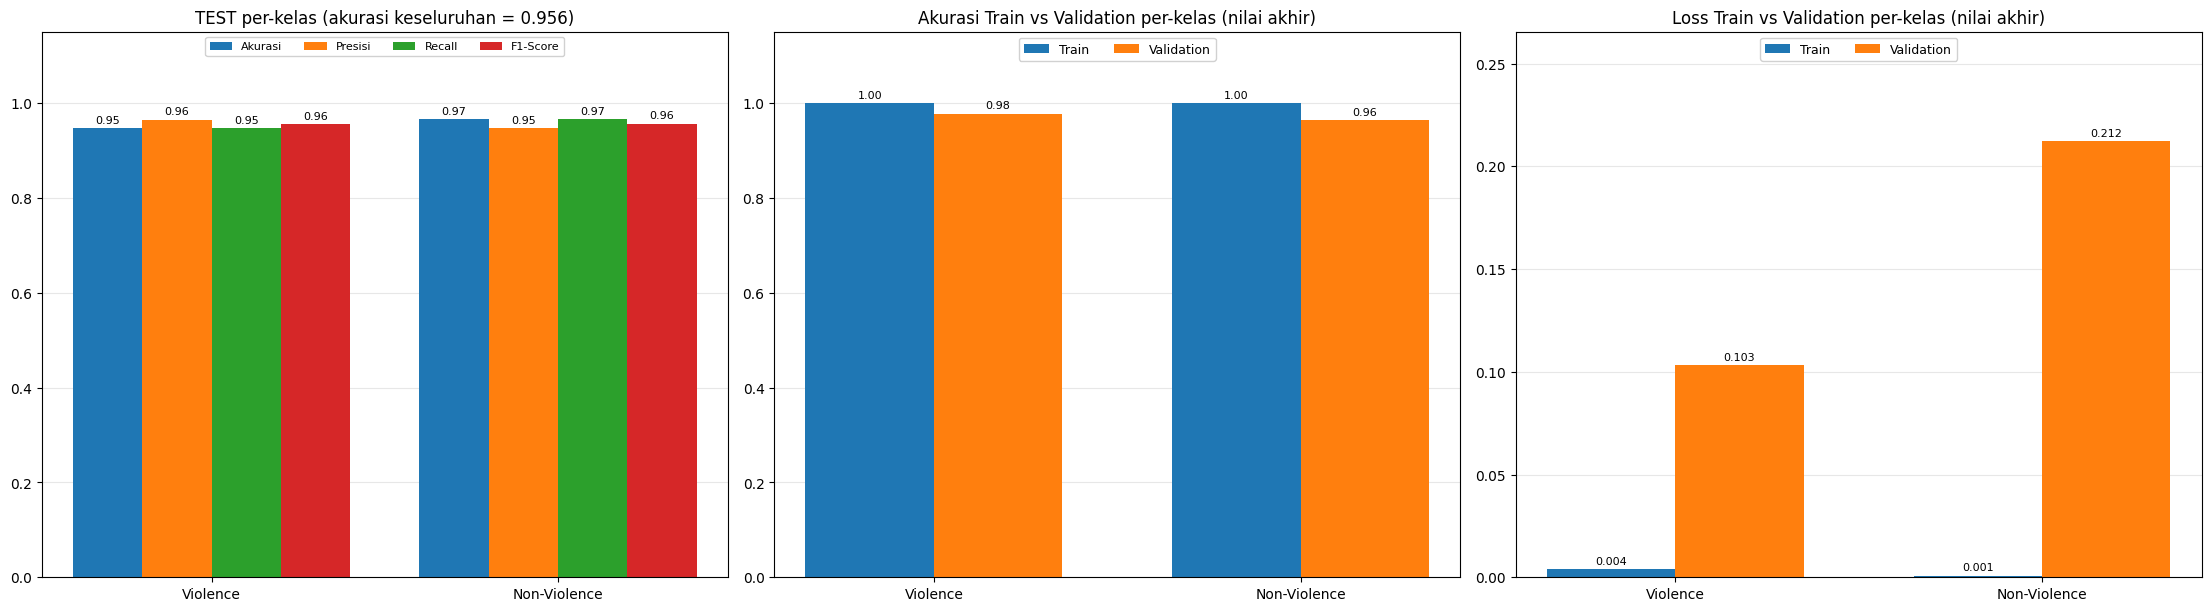

Grafik disimpan ke: /content/drive/MyDrive/KDRT/model_artifacts/per_class_metrics.png


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_score, recall_score, f1_score, accuracy_score,
)

# --- Selected configuration & threshold ---
sel = final_results["selected_configuration"]
selected_id = sel["experiment_id"]
THR = float(sel.get("validation_threshold", 0.5))
print(f"Selected model: {selected_id} | threshold = {THR:.2f}")

# --- Load final model + cache all splits (window level) ---
model = tf.keras.models.load_model(ARTIFACT_ROOT / "hybrid_model.h5")
all_rows = read_feature_manifest(FEATURE_MANIFEST, FEATURE_ROOT)


def split_probs(split):
    x, y, _ = build_cache(all_rows, split, CACHE_ROOT)
    p = predict(model, x, y, 32)
    return np.asarray(y, dtype=np.int32), np.asarray(p, dtype=np.float64)


y_train, p_train = split_probs("train")
y_val, p_val = split_probs("validation")
y_test, p_test = split_probs("test")

EPS = 1e-7


def per_class_acc(y, p, thr=THR):
    pred = (p >= thr).astype(int)
    acc_v = float(np.mean(pred[y == 1] == 1)) if np.any(y == 1) else float("nan")
    acc_n = float(np.mean(pred[y == 0] == 0)) if np.any(y == 0) else float("nan")
    return acc_v, acc_n


def per_class_loss(y, p):
    pc = np.clip(p, EPS, 1 - EPS)
    loss_v = float(np.mean(-np.log(pc[y == 1]))) if np.any(y == 1) else float("nan")
    loss_n = float(np.mean(-np.log(1 - pc[y == 0]))) if np.any(y == 0) else float("nan")
    return loss_v, loss_n


# ============ (1-8) TEST METRICS PER CLASS ============
pred_test = (p_test >= THR).astype(int)
acc_test_v, acc_test_n = per_class_acc(y_test, p_test)
prec_v = precision_score(y_test, pred_test, pos_label=1, zero_division=0)
prec_n = precision_score(y_test, pred_test, pos_label=0, zero_division=0)
rec_v = recall_score(y_test, pred_test, pos_label=1, zero_division=0)
rec_n = recall_score(y_test, pred_test, pos_label=0, zero_division=0)
f1_v = f1_score(y_test, pred_test, pos_label=1, zero_division=0)
f1_n = f1_score(y_test, pred_test, pos_label=0, zero_division=0)
overall_acc = accuracy_score(y_test, pred_test)

# ============ (9-16) TRAIN & VALIDATION PER CLASS (final values) ============
acc_tr_v, acc_tr_n = per_class_acc(y_train, p_train)
acc_va_v, acc_va_n = per_class_acc(y_val, p_val)
loss_tr_v, loss_tr_n = per_class_loss(y_train, p_train)
loss_va_v, loss_va_n = per_class_loss(y_val, p_val)

# --- Summary table ---
print("\n=== TEST per class (window-level, threshold={:.2f}) ===".format(THR))
print(f"Overall accuracy: {overall_acc:.4f}")
print(f"{'Metric':<12}{'Violence':>12}{'Non-Violence':>16}")
for _name, _v, _n in [("Accuracy", acc_test_v, acc_test_n),
                      ("Precision", prec_v, prec_n),
                      ("Recall", rec_v, rec_n),
                      ("F1-Score", f1_v, f1_n)]:
    print(f"{_name:<12}{_v:>12.4f}{_n:>16.4f}")

print("\n=== TRAIN & VALIDATION per class (final values) ===")
print(f"{'':<20}{'Violence':>12}{'Non-Violence':>16}")
print(f"{'Train accuracy':<20}{acc_tr_v:>12.4f}{acc_tr_n:>16.4f}")
print(f"{'Validation accuracy':<20}{acc_va_v:>12.4f}{acc_va_n:>16.4f}")
print(f"{'Train loss':<20}{loss_tr_v:>12.4f}{loss_tr_n:>16.4f}")
print(f"{'Validation loss':<20}{loss_va_v:>12.4f}{loss_va_n:>16.4f}")


# ============ SAVE PER-CLASS METRICS CSV ============
import pandas as pd

per_class_df = pd.DataFrame({
    "Metrik": ["Akurasi", "Presisi", "Recall", "F1-Score", "Akurasi", "Akurasi", "Loss", "Loss"],
    "Sumber": ["Test", "Test", "Test", "Test", "Train", "Validation", "Train", "Validation"],
    "Violence": [acc_test_v, prec_v, rec_v, f1_v, acc_tr_v, acc_va_v, loss_tr_v, loss_va_v],
    "Non-Violence": [acc_test_n, prec_n, rec_n, f1_n, acc_tr_n, acc_va_n, loss_tr_n, loss_va_n],
})

per_class_csv_path = ARTIFACT_ROOT / "per_class_metrics.csv"
per_class_df.to_csv(per_class_csv_path, index=False)
print("\nCSV data saved to:", per_class_csv_path)
display(per_class_df)


# ============ PLOT ============
def annotate(ax, fmt="{:.2f}"):
    for bar in ax.patches:
        h = bar.get_height()
        if np.isfinite(h):
            ax.annotate(fmt.format(h),
                        (bar.get_x() + bar.get_width() / 2, h),
                        ha="center", va="bottom", fontsize=8,
                        xytext=(0, 2), textcoords="offset points")


classes = ["Violence", "Non-Violence"]
x = np.arange(len(classes))

fig, axes = plt.subplots(1, 3, figsize=(22, 6), constrained_layout=True)

# --- Panel 1: TEST metrics per class (items 1-8): 4 bars per class ---
bw1 = 0.2
series1 = [("Accuracy", [acc_test_v, acc_test_n]),
           ("Precision", [prec_v, prec_n]),
           ("Recall", [rec_v, rec_n]),
           ("F1-Score", [f1_v, f1_n])]
for i, (label, vals) in enumerate(series1):
    offset = (i - 1.5) * bw1
    axes[0].bar(x + offset, vals, bw1, label=label)
axes[0].set_title(f"TEST per class (overall accuracy = {overall_acc:.3f})")
axes[0].set_xticks(x)
axes[0].set_xticklabels(classes)
axes[0].set_ylim(0, 1.15)
axes[0].legend(loc="upper center", ncol=4, fontsize=8, framealpha=0.9)
axes[0].grid(True, axis="y", alpha=0.3)
axes[0].set_axisbelow(True)
annotate(axes[0])

# --- Panel 2: Train vs Validation accuracy per class (items 9-12): 2 bars per class ---
bw2 = 0.35
axes[1].bar(x - bw2 / 2, [acc_tr_v, acc_tr_n], bw2, label="Train")
axes[1].bar(x + bw2 / 2, [acc_va_v, acc_va_n], bw2, label="Validation")
axes[1].set_title("Train vs Validation accuracy per class (final values)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(classes)
axes[1].set_ylim(0, 1.15)
axes[1].legend(loc="upper center", ncol=2, fontsize=9, framealpha=0.9)
axes[1].grid(True, axis="y", alpha=0.3)
axes[1].set_axisbelow(True)
annotate(axes[1])

# --- Panel 3: Train vs Validation loss per class (items 13-16): 2 bars per class ---
axes[2].bar(x - bw2 / 2, [loss_tr_v, loss_tr_n], bw2, label="Train")
axes[2].bar(x + bw2 / 2, [loss_va_v, loss_va_n], bw2, label="Validation")
_loss_max = np.nanmax([loss_tr_v, loss_tr_n, loss_va_v, loss_va_n])
axes[2].set_title("Train vs Validation loss per class (final values)")
axes[2].set_xticks(x)
axes[2].set_xticklabels(classes)
axes[2].set_ylim(0, _loss_max * 1.25 if np.isfinite(_loss_max) and _loss_max > 0 else 1.0)
axes[2].legend(loc="upper center", ncol=2, fontsize=9, framealpha=0.9)
axes[2].grid(True, axis="y", alpha=0.3)
axes[2].set_axisbelow(True)
annotate(axes[2], fmt="{:.3f}")

out_path = ARTIFACT_ROOT / "per_class_metrics.png"
fig.savefig(out_path, dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved to:", out_path)